# Análisis de valores faltantes del dataset

Esta sección evalúa los valores faltantes del dataset

**Criterio utilizado:**

Se considera valor faltante únicamente cuando la celda:

- está vacía;
- contiene el carácter `-`;
- contiene el carácter `_`.

Los valores `0` **no se consideran faltantes**, porque pueden representar una respuesta válida o un código registrado.


## 1. Cargar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
import os

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Cargar el archivo Excel

Ejecutar esta celda y subir el archivo `DataSet.xlsx`.

Si el archivo ya está disponible en el entorno de Colab, también se puede indicar su ruta directamente en la variable `ruta_archivo`.


In [2]:
# Opción A: subir archivo desde la computadora
from google.colab import files

uploaded = files.upload()

# Tomar automáticamente el primer archivo subido
nombre_archivo = list(uploaded.keys())[0]
ruta_archivo = nombre_archivo

print(f"Archivo cargado: {ruta_archivo}")

Saving DataSet.xlsx to DataSet.xlsx
Archivo cargado: DataSet.xlsx


## 3. Leer el dataset completo

Este bloque lee el archivo Excel. Si el archivo tiene más de una hoja, por defecto toma la primera hoja.
Para este trabajo se espera que el dataset ya esté unificado en una sola hoja.


In [3]:
# Leer nombres de hojas
excel = pd.ExcelFile(ruta_archivo)
print("Hojas encontradas:", excel.sheet_names)

# Leer la primera hoja
hoja = excel.sheet_names[0]
df = pd.read_excel(ruta_archivo, sheet_name=hoja)

print(f"Hoja leída: {hoja}")
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")

df.head()

Hojas encontradas: ['Hoja1']
Hoja leída: Hoja1
Dimensiones del dataset: 978 filas x 125 columnas


,alumno,nota,tecnologia_pc_casa,tecnologia_pc_trabajo,tecnologia_pc_universidad,tecnologia_pc_otro_lugar,tecnologia_int_casa,tecnologia_int_trabajo,tecnologia_int_universidad,tecnologia_int_otro_lugar,deportes,deportes_universidad,deportes_gimnasio,deportes_particular,deportes_otro_lugar,deportes_basquet,deportes_futbol,deportes_gimnasia,deportes_handball,deportes_natacion,deportes_tenis,deportes_voley,deportes_otros,nivel_idioma_ingles,nivel_idioma_aleman,nivel_idioma_frances,nivel_idioma_italiano,nivel_idioma_portugues,nivel_idioma_chino,idioma_otro,nivel_idioma_otro,tecnologia_int_movil,condicion_discapacidad,tiene_cud,disc_auditiva,aud_tipo,aud_lenguaje_senias,aud_lenguaje_labial,aud_comunicacion_otra,aud_apoyo_vida_diaria,aud_req_interprete_lengua_senias,aud_req_aro_magnetico,aud_req_otros_apoyos,aud_otros_apoyos,disc_visual,vis_dificultad_para_ver,vis_apoyo_vida_diaria,vis_req_archivo_audio,vis_req_texto_digital,vis_req_texto_braile,vis_req_otros_apoyos,vis_otros_apoyos,disc_motora,mot_apoyo_vida_diaria,mot_req_apoyo_aula,mot_apoyo_aula,mot_req_otros_apoyos,mot_otros_apoyos,disc_cond_psicosocial,psi_descripcion,psi_apoyo_vida_diaria,psi_req_otros_apoyos,psi_otros_apoyos,disc_otra,otra_descripcion,otra_req_apoyo_vida_diaria,otra_apoyo_vida_diaria,informacion_importante,costeo_estudios_familiar,costeo_estudios_plan_social,costeo_estudios_trabajo,costeo_estudios_beca,costeo_estudios_otro,costeo_estudios_descripcion,beca,beca_fuente_universidad,beca_fuente_nacional,beca_fuente_provincial,beca_fuente_municipal,beca_fuente_internacional,beca_fuente_otra,beca_tipo_economica,beca_tipo_servicios,beca_tipo_investigacion,beca_economica_transporte,beca_economica_efectivo,beca_economica_fotocopias,beca_economica_habitacional,beca_economica_comedor,trabajo_existe,trabajo_hace,trabajo_familiar,trabajo_con_descuentos_jubilatorios,trabajo_recibe_pago,trabajo_ocupacion,trabajo_hora_sem,trabajo_carrera,trabajo_tarea_descripcion,estado_civil,unido_hecho,situacion_padre,situacion_madre,cantidad_hijos,cantidad_familia,turno_preferido,cobertura_salud,tipo_vivienda,vive_con,procedencia_calle,procedencia_numero,procedencia_piso,procedencia_departamento,procedencia_unidad,procedencia_localidad,procedencia_barrio,procedencia_codigo_postal,es_celiaco,mot_vocacion,mot_sugerencia_familiar,mot_reconocimiento_social,mot_insercion_laboral,mot_perfil_profesional,mot_mejora_economica,mot_util_sociedad,mot_otros_p
0,25342,A,S,S,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,N,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,S,N,N,1.0,4.0,1.0,NaN,2,N,V,V,0,0,3.0,2,5.0,3.0,Jose Hernandez 525,525,0,0,0,5436,Hipotecario,3530.0,N,N,S,N,N,N,N,N,N
1,25567,R,S,N,S,N,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,N,N,N,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,3.0,S,N,S,2.0,2.0,3.0,NaN,1,N,N,V,0,0,NaN,1,NaN,NaN,17 Entre 0 Y 00 Superiora Palmira,172,_,_,_,6036,_,3700.0,N,N,N,N,N,N,N,N,N
2,28277,U,S,N,N,N,S,N,N,N,S,N,N,S,N,N,N,N,N,N,N,N,S,3.0,4.0,3.0,4.0,3.0,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,NaN,Compra Y Venta,1,N,V,V,0,3,1.0,5,5.0,3.0,San JosÃ©,10,-,-,-,5342,San JosÃ©,3514.0,N,N,N,N,S,N,N,N,N
3,27014,A,S,N,S,N,S,N,S,N,S,N,N,S,N,S,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,2.0,TÃ©cnico InformÃ¡tico,1,N,V,V,0,0,1.0,5,6.0,3.0,Mza 4 Pc 11,-,-,-,-,6167,Victor Arrudi,3730.0,N,N,S,S,S,S,S,S,N
4,32446,R,S,N,N,N,S,N,N,S,S,N,N,S,N,N,N,N,N,N,N,S,N,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N

## 4. Función para detectar valores faltantes

La función aplica el criterio definido:

`faltante = celda vacía OR "-" OR "_"`

Los valores cero (`0`) no son tratados como faltantes.


In [4]:
def mascara_valores_faltantes(serie):
    """
    Devuelve una máscara booleana donde True indica valor faltante.

    Criterio:
    - NaN / celda vacía
    - cadena vacía luego de quitar espacios
    - "-"
    - "_"

    Importante:
    - El valor 0 NO se considera faltante.
    """
    s = serie.copy()

    # Celdas vacías reales de Excel / pandas
    faltante_nan = s.isna()

    # Para evaluar símbolos, convertir a string solo las celdas no nulas
    s_str = s.astype("string").str.strip()

    faltante_vacio_texto = s_str.eq("")
    faltante_guion = s_str.eq("-")
    faltante_guion_bajo = s_str.eq("_")

    return faltante_nan | faltante_vacio_texto | faltante_guion | faltante_guion_bajo


def contar_componentes_faltantes(serie):
    """
    Cuenta por separado:
    - celdas vacías reales o texto vacío
    - celdas con "-"
    - celdas con "_"
    """
    s = serie.copy()
    s_str = s.astype("string").str.strip()

    vacias = (s.isna() | s_str.eq("")).sum()
    guion = s_str.eq("-").sum()
    guion_bajo = s_str.eq("_").sum()

    total = (s.isna() | s_str.eq("") | s_str.eq("-") | s_str.eq("_")).sum()

    return vacias, guion, guion_bajo, total


print("Funciones definidas correctamente.")

Funciones definidas correctamente.


## 5. Resumen general de valores faltantes

In [5]:
total_filas, total_columnas = df.shape
total_celdas = total_filas * total_columnas

vacias_total = 0
guion_total = 0
guion_bajo_total = 0
faltantes_total = 0

for col in df.columns:
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(df[col])
    vacias_total += vacias
    guion_total += guion
    guion_bajo_total += guion_bajo
    faltantes_total += total

porcentaje_faltantes = faltantes_total / total_celdas * 100

resumen_general = pd.DataFrame({
    "concepto": [
        "Filas totales",
        "Columnas totales",
        "Celdas totales",
        "Celdas vacías",
        "Celdas con '-'",
        "Celdas con '_'",
        "Valores faltantes totales",
        "Porcentaje de valores faltantes"
    ],
    "valor": [
        total_filas,
        total_columnas,
        total_celdas,
        int(vacias_total),
        int(guion_total),
        int(guion_bajo_total),
        int(faltantes_total),
        round(porcentaje_faltantes, 2)
    ]
})

resumen_general

,concepto,valor
0,Filas totales,978.00
1,Columnas totales,125.00
2,Celdas totales,122250.00
3,Celdas vacías,23782.00
4,Celdas con '-',759.00
5,Celdas con '_',8.00
6,Valores faltantes totales,24549.00
7,Porcentaje de valores faltantes,20.08


## 6. Análisis de valores faltantes por variable

In [6]:
analisis_columnas = []

for col in df.columns:
    serie = df[col]
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(serie)
    mascara = mascara_valores_faltantes(serie)

    no_faltantes = len(serie) - total

    # Valores únicos no faltantes
    valores_no_faltantes = serie[~mascara]
    valores_unicos = valores_no_faltantes.nunique(dropna=True)

    # Valor más frecuente no faltante
    if len(valores_no_faltantes) > 0:
        moda = valores_no_faltantes.mode(dropna=True)
        valor_mas_frecuente = moda.iloc[0] if len(moda) > 0 else np.nan
    else:
        valor_mas_frecuente = np.nan

    analisis_columnas.append({
        "variable": col,
        "tipo_dato_pandas": str(serie.dtype),
        "total_registros": len(serie),
        "vacias": int(vacias),
        "guion": int(guion),
        "guion_bajo": int(guion_bajo),
        "faltantes_total": int(total),
        "porcentaje_faltantes": round(total / len(serie) * 100, 2),
        "no_faltantes": int(no_faltantes),
        "porcentaje_no_faltantes": round(no_faltantes / len(serie) * 100, 2),
        "valores_unicos_no_faltantes": int(valores_unicos),
        "valor_mas_frecuente_no_faltante": valor_mas_frecuente
    })

df_faltantes = pd.DataFrame(analisis_columnas)
df_faltantes = df_faltantes.sort_values(
    by=["faltantes_total", "porcentaje_faltantes"],
    ascending=False
).reset_index(drop=True)

df_faltantes.head(30)

,variable,tipo_dato_pandas,total_registros,vacias,guion,guion_bajo,faltantes_total,porcentaje_faltantes,no_faltantes,porcentaje_no_faltantes,valores_unicos_no_faltantes,valor_mas_frecuente_no_faltante
0,aud_comunicacion_otra,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
1,aud_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
2,aud_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
3,vis_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
4,mot_apoyo_aula,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
5,mot_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
6,psi_descripcion,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
7,psi_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
8,psi_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
9,otra_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN


## 7. Variables sin valores faltantes y variables completamente vacías

In [7]:
variables_sin_faltantes = df_faltantes[df_faltantes["faltantes_total"] == 0].copy()
variables_100_faltantes = df_faltantes[df_faltantes["porcentaje_faltantes"] == 100].copy()

print(f"Variables sin valores faltantes: {len(variables_sin_faltantes)}")
print(f"Variables con 100% de valores faltantes: {len(variables_100_faltantes)}")

display(variables_sin_faltantes[["variable", "tipo_dato_pandas", "valores_unicos_no_faltantes"]])
display(variables_100_faltantes[["variable", "faltantes_total", "porcentaje_faltantes"]])

Variables sin valores faltantes: 84
Variables con 100% de valores faltantes: 10


,variable,tipo_dato_pandas,valores_unicos_no_faltantes
41,alumno,int64,343
42,nota,object,3
43,tecnologia_pc_casa,object,2
44,tecnologia_pc_trabajo,object,2
45,tecnologia_pc_universidad,object,2
46,tecnologia_pc_otro_lugar,object,2
47,deportes,object,2
48,deportes_universidad,object,2
49,deportes_gimnasio,object,2
50,deportes_particular,object,2


,variable,faltantes_total,porcentaje_faltantes
0,aud_comunicacion_otra,978,100.0
1,aud_apoyo_vida_diaria,978,100.0
2,aud_otros_apoyos,978,100.0
3,vis_otros_apoyos,978,100.0
4,mot_apoyo_aula,978,100.0
5,mot_otros_apoyos,978,100.0
6,psi_descripcion,978,100.0
7,psi_apoyo_vida_diaria,978,100.0
8,psi_otros_apoyos,978,100.0
9,otra_apoyo_vida_diaria,978,100.0


## 8. Distribución de variables según porcentaje de faltantes

In [8]:
def clasificar_rango_faltantes(p):
    if p == 0:
        return "0% faltantes"
    elif p == 100:
        return "100% faltantes"
    elif 90 <= p < 100:
        return "90% a 99%"
    elif 75 <= p < 90:
        return "75% a 89%"
    elif 50 <= p < 75:
        return "50% a 74%"
    elif 25 <= p < 50:
        return "25% a 49%"
    elif 1 <= p < 25:
        return "1% a 24%"
    else:
        return "Menos de 1%"

orden_rangos = [
    "100% faltantes",
    "90% a 99%",
    "75% a 89%",
    "50% a 74%",
    "25% a 49%",
    "1% a 24%",
    "Menos de 1%",
    "0% faltantes"
]

df_faltantes["rango_faltantes"] = df_faltantes["porcentaje_faltantes"].apply(clasificar_rango_faltantes)

resumen_rangos = (
    df_faltantes["rango_faltantes"]
    .value_counts()
    .reindex(orden_rangos, fill_value=0)
    .reset_index()
)

resumen_rangos.columns = ["rango_faltantes", "cantidad_variables"]
resumen_rangos

,rango_faltantes,cantidad_variables
0,100% faltantes,10
1,90% a 99%,12
2,75% a 89%,0
3,50% a 74%,0
4,25% a 49%,6
5,1% a 24%,7
6,Menos de 1%,6
7,0% faltantes,84


## 9. Gráficos de valores faltantes

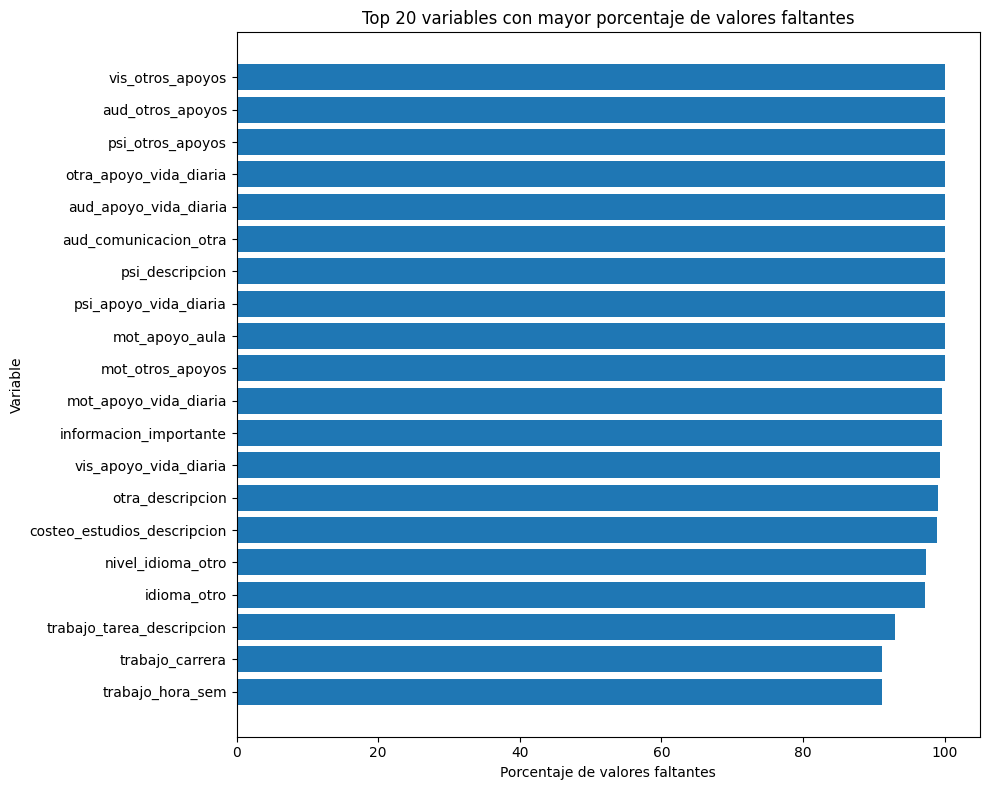

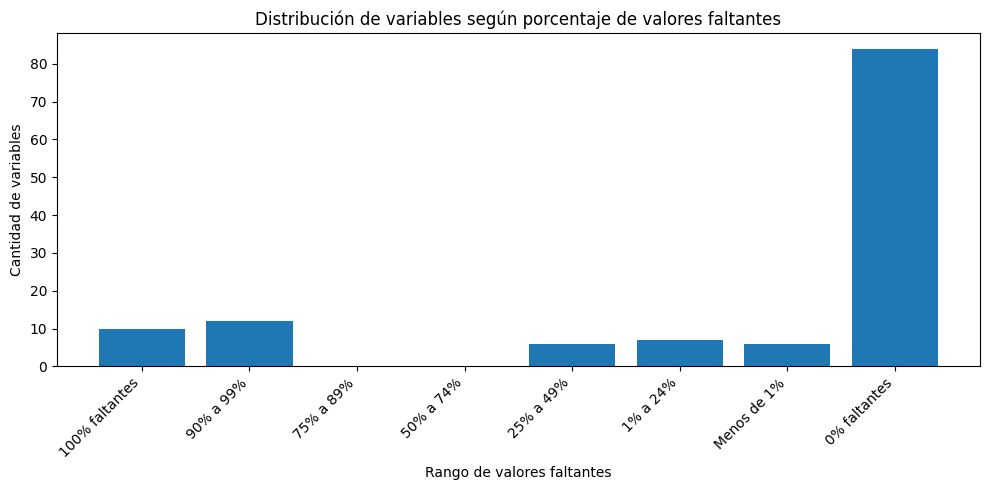

In [9]:
carpeta_salida = Path("salidas_valores_faltantes")
carpeta_salida.mkdir(exist_ok=True)

# Gráfico 1: Top 20 variables con más faltantes
top20 = df_faltantes.head(20).sort_values("porcentaje_faltantes", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top20["variable"], top20["porcentaje_faltantes"])
plt.xlabel("Porcentaje de valores faltantes")
plt.ylabel("Variable")
plt.title("Top 20 variables con mayor porcentaje de valores faltantes")
plt.tight_layout()
plt.savefig(carpeta_salida / "top20_variables_faltantes.png", dpi=300, bbox_inches="tight")
plt.show()

# Gráfico 2: Distribución por rangos
plt.figure(figsize=(10, 5))
plt.bar(resumen_rangos["rango_faltantes"], resumen_rangos["cantidad_variables"])
plt.xlabel("Rango de valores faltantes")
plt.ylabel("Cantidad de variables")
plt.title("Distribución de variables según porcentaje de valores faltantes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(carpeta_salida / "distribucion_rangos_faltantes.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Análisis de faltantes por fila

Este bloque permite detectar registros con mucha información incompleta.


In [10]:
faltantes_por_fila = []

for idx, fila in df.iterrows():
    mascara_fila = fila.apply(lambda x: pd.isna(x) or str(x).strip() in ["", "-", "_"])
    total_faltantes_fila = int(mascara_fila.sum())

    faltantes_por_fila.append({
        "indice_fila": idx,
        "faltantes_total": total_faltantes_fila,
        "porcentaje_faltantes": round(total_faltantes_fila / total_columnas * 100, 2)
    })

df_faltantes_fila = pd.DataFrame(faltantes_por_fila)

print("Resumen de faltantes por fila:")
display(df_faltantes_fila["faltantes_total"].describe())

df_faltantes_fila.sort_values("faltantes_total", ascending=False).head(20)

Resumen de faltantes por fila:


,faltantes_total
count,978.000000
mean,25.101227
std,3.281875
min,14.000000
25%,22.000000
50%,25.000000
75%,28.000000
max,34.000000


,indice_fila,faltantes_total,porcentaje_faltantes
964,964,34,27.2
899,899,34,27.2
850,850,33,26.4
915,915,33,26.4
956,956,33,26.4
354,354,33,26.4
311,311,33,26.4
7,7,33,26.4
891,891,33,26.4
842,842,32,25.6


## 11. Exportar resultados

Se exportan:

- resumen general;
- análisis por variable;
- distribución por rangos;
- análisis por fila;
- variables sin faltantes;
- variables completamente faltantes;
- gráficos en PNG;
- archivo ZIP con todos los resultados.


In [11]:
archivo_excel_salida = carpeta_salida / "analisis_valores_faltantes.xlsx"

with pd.ExcelWriter(archivo_excel_salida, engine="openpyxl") as writer:
    resumen_general.to_excel(writer, sheet_name="resumen_general", index=False)
    df_faltantes.to_excel(writer, sheet_name="faltantes_por_variable", index=False)
    resumen_rangos.to_excel(writer, sheet_name="rangos_faltantes", index=False)
    df_faltantes_fila.to_excel(writer, sheet_name="faltantes_por_fila", index=False)
    variables_sin_faltantes.to_excel(writer, sheet_name="variables_sin_faltantes", index=False)
    variables_100_faltantes.to_excel(writer, sheet_name="variables_100_faltantes", index=False)

# Exportar también CSV
df_faltantes.to_csv(carpeta_salida / "faltantes_por_variable.csv", index=False, encoding="utf-8-sig")
resumen_general.to_csv(carpeta_salida / "resumen_general.csv", index=False, encoding="utf-8-sig")
resumen_rangos.to_csv(carpeta_salida / "rangos_faltantes.csv", index=False, encoding="utf-8-sig")
df_faltantes_fila.to_csv(carpeta_salida / "faltantes_por_fila.csv", index=False, encoding="utf-8-sig")

# Crear ZIP
archivo_zip = "resultados_valores_faltantes.zip"

with zipfile.ZipFile(archivo_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
    for archivo in carpeta_salida.iterdir():
        zipf.write(archivo, arcname=archivo.name)

print(f"Archivo Excel generado: {archivo_excel_salida}")
print(f"Archivo ZIP generado: {archivo_zip}")

Archivo Excel generado: salidas_valores_faltantes/analisis_valores_faltantes.xlsx
Archivo ZIP generado: resultados_valores_faltantes.zip


## 12. Descargar resultados en Colab

In [12]:
from google.colab import files

files.download(str(archivo_excel_salida))
files.download(archivo_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Informe

Depuración inicial del data set:

In [ ]:
# ============================================================
# DEPURACIÓN BÁSICA DEL DATASET PARA EDA
# ============================================================
# Criterio aplicado:
# - Se consideran valores faltantes:
#   1) celdas vacías
#   2) celdas con "-"
#   3) celdas con "_"
#
# - El valor 0 NO se considera faltante.
# ============================================================

df_depurado = df_original.copy()

# ------------------------------------------------------------
# 1. Quitar espacios al inicio y al final en valores de texto
# ------------------------------------------------------------

for col in df_depurado.columns:
    if df_depurado[col].dtype == "object":
        df_depurado[col] = df_depurado[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

# ------------------------------------------------------------
# 2. Reemplazar valores faltantes definidos por NaN
# ------------------------------------------------------------

valores_faltantes = ["", "-", "_"]

df_depurado = df_depurado.replace(valores_faltantes, np.nan)

# ------------------------------------------------------------
# 3. Mostrar dimensiones del dataset depurado
# ------------------------------------------------------------

print("Depuración básica finalizada.")
print("Dimensiones del dataset depurado:")
print(f"Filas: {df_depurado.shape[0]}")
print(f"Columnas: {df_depurado.shape[1]}")

display(df_depurado.head())

In [ ]:
# ============================================================
# VERIFICACIÓN RÁPIDA DE VALORES FALTANTES
# ============================================================

filas, columnas = df_depurado.shape
total_celdas = filas * columnas

total_faltantes = df_depurado.isna().sum().sum()
porcentaje_faltantes = (total_faltantes / total_celdas) * 100

print("Resumen de valores faltantes")
print("----------------------------")
print(f"Filas: {filas}")
print(f"Columnas: {columnas}")
print(f"Celdas totales: {total_celdas}")
print(f"Valores faltantes: {total_faltantes}")
print(f"Porcentaje de valores faltantes: {porcentaje_faltantes:.2f}%")

In [ ]:
# ============================================================
# VALIDACIÓN DE LA VARIABLE OBJETIVO ORIGINAL: nota
# ============================================================

if "nota" in df_depurado.columns:
    distribucion_nota = (
        df_depurado["nota"]
        .value_counts(dropna=False)
        .reset_index()
    )

    distribucion_nota.columns = ["nota", "cantidad"]
    distribucion_nota["porcentaje"] = (
        distribucion_nota["cantidad"] / len(df_depurado) * 100
    ).round(2)

    display(distribucion_nota)
else:
    print("La columna 'nota' no existe en el dataset.")

In [ ]:
# ============================================================
# EXPORTAR DATASET DEPURADO
# ============================================================

nombre_salida_excel = "DataSet_depurado_basico_EDA.xlsx"
nombre_salida_csv = "DataSet_depurado_basico_EDA.csv"

# Exportar Excel
with pd.ExcelWriter(nombre_salida_excel, engine="openpyxl") as writer:
    df_depurado.to_excel(writer, sheet_name="Datos_depurados", index=False)

print("Archivos generados:")
print(nombre_salida_excel)

# ============================================================
# DESCARGAR ARCHIVO GENERADO
# ============================================================

files.download(nombre_salida_excel)



Análisis de variables predictoras

Prepararación del datset para la etapa exploratoria - Se eliminan las columnas vacías

In [ ]:
# ============================================================
# PREPARACIÓN DEL DATASET PARA ANÁLISIS EXPLORATORIO
# ============================================================
# Se parte de df_depurado, que conserva las variables originales
# y tiene normalizados los valores faltantes.
#
# En esta etapa se eliminan únicamente las columnas con 100%
# de valores faltantes.
# ============================================================

df_eda = df_depurado.copy()

columnas_100_faltantes = df_eda.columns[df_eda.isna().all()].tolist()

print("Columnas con 100% de valores faltantes:")
for col in columnas_100_faltantes:
    print("-", col)

df_eda = df_eda.drop(columns=columnas_100_faltantes)

print("\nDimensiones del dataset depurado básico:")
print(df_depurado.shape)

print("\nDimensiones del dataset para EDA:")
print(df_eda.shape)

In [ ]:
# ============================================================
# CLASIFICACIÓN PRELIMINAR DE VARIABLES
# ============================================================

def clasificar_variable(serie):
    serie_no_nula = serie.dropna()
    n_unicos = serie_no_nula.nunique()

    if n_unicos <= 1:
        return "sin_variabilidad"

    valores = set(serie_no_nula.astype(str).unique())

    if n_unicos == 2 and valores.issubset({"S", "N", "0", "1", "0.0", "1.0"}):
        return "binaria"

    if pd.api.types.is_numeric_dtype(serie):
        if n_unicos <= 10:
            return "ordinal_discreta"
        else:
            return "numerica_o_codigo"

    if n_unicos > 30:
        return "alta_cardinalidad_texto"

    return "categorica_nominal"


resumen_variables = []

for col in df_eda.columns:
    if col == variable_objetivo:
        tipo = "objetivo"
    elif col in variables_identificatorias:
        tipo = "identificador"
    else:
        tipo = clasificar_variable(df_eda[col])

    resumen_variables.append({
        "variable": col,
        "tipo_variable": tipo,
        "tipo_dato_pandas": str(df_eda[col].dtype),
        "valores_unicos": df_eda[col].nunique(dropna=True),
        "faltantes": df_eda[col].isna().sum(),
        "porcentaje_faltantes": round(df_eda[col].isna().mean() * 100, 2)
    })

resumen_variables = pd.DataFrame(resumen_variables)

display(resumen_variables)

print("\nResumen por tipo de variable:")
display(
    resumen_variables["tipo_variable"]
    .value_counts()
    .reset_index()
    .rename(columns={"index": "tipo_variable", "tipo_variable": "cantidad"})
)

In [ ]:
# ============================================================
# VARIABLES SIN VARIABILIDAD
# ============================================================
# Estas variables tienen un único valor observado.
# No aportan capacidad discriminante para el análisis predictivo.
# ============================================================

variables_sin_variabilidad = resumen_variables[
    resumen_variables["tipo_variable"] == "sin_variabilidad"
]["variable"].tolist()

print("Cantidad de variables sin variabilidad:", len(variables_sin_variabilidad))

for col in variables_sin_variabilidad:
    print("-", col)

In [ ]:
# ============================================================
# SELECCIÓN DE VARIABLES CANDIDATAS PARA ANÁLISIS GRÁFICO
# ============================================================

tipos_validos_para_eda = [
    "binaria",
    "categorica_nominal",
    "ordinal_discreta",
    "numerica_o_codigo"
]

variables_eda = resumen_variables[
    resumen_variables["tipo_variable"].isin(tipos_validos_para_eda)
]["variable"].tolist()

# Excluir identificadores por seguridad
variables_eda = [
    col for col in variables_eda
    if col not in variables_identificatorias and col != variable_objetivo
]

print("Cantidad de variables candidatas para EDA:", len(variables_eda))
display(resumen_variables[resumen_variables["variable"].isin(variables_eda)])

In [ ]:
# ============================================================
# FUNCIÓN PARA ANALIZAR CUALQUIER VARIABLE CONTRA nota
# ============================================================

def analizar_variable_vs_nota(df, variable, objetivo="nota"):
    print("=" * 80)
    print(f"Variable analizada: {variable}")
    print("=" * 80)

    tabla_abs = pd.crosstab(df[variable], df[objetivo], dropna=False)
    tabla_pct = pd.crosstab(df[variable], df[objetivo], normalize="index", dropna=False) * 100

    tabla_pct = tabla_pct.round(2)

    print("\nFrecuencias absolutas:")
    display(tabla_abs)

    print("\nPorcentajes por categoría de la variable:")
    display(tabla_pct)

    return tabla_abs, tabla_pct

In [ ]:
# ejemplo de uso
tabla_abs, tabla_pct = analizar_variable_vs_nota(df_eda, "tecnologia_pc_casa")

In [ ]:
# ============================================================
# GRÁFICO DE DISTRIBUCIÓN DE nota POR VARIABLE
# ============================================================

import matplotlib.pyplot as plt

def graficar_variable_vs_nota(df, variable, objetivo="nota"):
    tabla_pct = pd.crosstab(df[variable], df[objetivo], normalize="index", dropna=False) * 100
    tabla_pct = tabla_pct.round(2)

    ax = tabla_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f"Distribución porcentual de {objetivo} según {variable}")
    plt.xlabel(variable)
    plt.ylabel("Porcentaje")
    plt.legend(title=objetivo)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Ejemplo
graficar_variable_vs_nota(df_eda, "tecnologia_pc_casa")

In [ ]:
# ============================================================
# DEFINICIÓN DE GRUPOS DE VARIABLES PARA EL ANÁLISIS EXPLORATORIO
# ============================================================

grupos_variables = {
    "Tecnológicas": [
        "tecnologia_pc_casa",
        "tecnologia_pc_trabajo",
        "tecnologia_pc_universidad",
        "tecnologia_int_casa",
        "tecnologia_int_universidad",
        "tecnologia_int_movil"
    ],

    "Hábitos y actividades": [
        "deportes",
        "deportes_universidad",
        "deportes_gimnasio",
        "deportes_particular",
        "deportes_futbol",
        "deportes_otros"
    ],

    "Idiomas": [
        "nivel_idioma_ingles",
        "nivel_idioma_portugues",
        "nivel_idioma_frances",
        "nivel_idioma_aleman"
    ],

    "Socioeconómicas": [
        "costeo_estudios_familiar",
        "costeo_estudios_trabajo",
        "costeo_estudios_beca",
        "beca",
        "beca_tipo_economica",
        "beca_economica_transporte",
        "beca_economica_comedor"
    ],

    "Laborales": [
        "trabajo_existe",
        "trabajo_hace",
        "trabajo_ocupacion",
        "trabajo_hora_sem",
        "trabajo_carrera",
        "trabajo_recibe_pago"
    ],

    "Familiares y personales": [
        "estado_civil",
        "situacion_padre",
        "situacion_madre",
        "cantidad_hijos",
        "cantidad_familia",
        "vive_con",
        "cobertura_salud",
        "tipo_vivienda"
    ],

    "Territoriales": [
        "procedencia_localidad",
        "procedencia_codigo_postal",
        "procedencia_barrio"
    ],

    "Motivacionales": [
        "mot_vocacion",
        "mot_sugerencia_familiar",
        "mot_reconocimiento_social",
        "mot_insercion_laboral",
        "mot_perfil_profesional",
        "mot_mejora_economica",
        "mot_util_sociedad",
        "mot_otros_p"
    ]
}

# Verificar qué variables existen realmente en el dataset
for grupo, variables in grupos_variables.items():
    existentes = [v for v in variables if v in df_eda.columns]
    faltantes = [v for v in variables if v not in df_eda.columns]

    print(f"\nGrupo: {grupo}")
    print(f"Variables encontradas: {len(existentes)}")
    print(existentes)

    if faltantes:
        print("Variables no encontradas:")
        print(faltantes)

In [ ]:
# ============================================================
# FUNCIÓN PARA GENERAR TABLAS CRUZADAS VARIABLE x NOTA
# ============================================================

def tabla_variable_vs_nota(df, variable, objetivo="nota"):
    """
    Genera tabla de frecuencias absolutas y porcentajes por categoría
    de una variable predictora respecto de la variable objetivo nota.
    """

    tabla_abs = pd.crosstab(
        df[variable],
        df[objetivo],
        dropna=False
    )

    tabla_pct = pd.crosstab(
        df[variable],
        df[objetivo],
        normalize="index",
        dropna=False
    ) * 100

    tabla_pct = tabla_pct.round(2)

    return tabla_abs, tabla_pct

In [ ]:
# ============================================================
# FUNCIÓN PARA GRAFICAR DISTRIBUCIÓN PORCENTUAL DE NOTA
# ============================================================

import matplotlib.pyplot as plt
import os

def graficar_variable_vs_nota(df, variable, objetivo="nota", carpeta_salida=None):
    """
    Genera un gráfico de barras apiladas porcentuales para analizar
    la distribución de nota según una variable predictora.
    """

    tabla_pct = pd.crosstab(
        df[variable],
        df[objetivo],
        normalize="index",
        dropna=False
    ) * 100

    tabla_pct = tabla_pct.round(2)

    ax = tabla_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    plt.title(f"Distribución porcentual de {objetivo} según {variable}")
    plt.xlabel(variable)
    plt.ylabel("Porcentaje")
    plt.legend(title=objetivo)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if carpeta_salida is not None:
        os.makedirs(carpeta_salida, exist_ok=True)
        nombre_archivo = f"{variable}_vs_{objetivo}.png"
        ruta = os.path.join(carpeta_salida, nombre_archivo)
        plt.savefig(ruta, dpi=300, bbox_inches="tight")

    plt.show()

In [ ]:
# ============================================================
# PRIMER ANÁLISIS INDIVIDUAL
# ============================================================

variable_prueba = "tecnologia_pc_casa"

if variable_prueba in df_eda.columns:
    tabla_abs, tabla_pct = tabla_variable_vs_nota(df_eda, variable_prueba)

    print("Frecuencias absolutas")
    display(tabla_abs)

    print("Porcentajes por categoría")
    display(tabla_pct)

    graficar_variable_vs_nota(df_eda, variable_prueba)
else:
    print(f"La variable {variable_prueba} no existe en el dataset.")

In [ ]:
# ==================================================================
# ANÁLISIS AUTOMÁTICO DE TODAS LAS VARIABLES POR GRUPO DE VARIABLES
# ==================================================================

resultados_tablas_abs = {}
resultados_tablas_pct = {}

carpeta_graficos = "graficos_eda_variables"

for grupo, variables in grupos_variables.items():
    print("\n" + "=" * 100)
    print(f"GRUPO: {grupo}")
    print("=" * 100)

    variables_existentes = [v for v in variables if v in df_eda.columns]

    for variable in variables_existentes:
        print("\n" + "-" * 80)
        print(f"Variable: {variable}")
        print("-" * 80)

        tabla_abs, tabla_pct = tabla_variable_vs_nota(df_eda, variable)

        resultados_tablas_abs[variable] = tabla_abs
        resultados_tablas_pct[variable] = tabla_pct

        print("Frecuencias absolutas:")
        display(tabla_abs)

        print("Porcentajes por categoría:")
        display(tabla_pct)

        graficar_variable_vs_nota(
            df_eda,
            variable,
            carpeta_salida=carpeta_graficos
        )

In [ ]:
# ============================================================
# RANKING EXPLORATORIO DE VARIABLES SEGÚN DIFERENCIA ENTRE CLASES
# ============================================================
# Este ranking ayuda a detectar variables donde cambia más la proporción de A, R y U entre categorías.
# Para cada variable se calcula la diferencia máxima observada
# en el porcentaje de cada clase de nota entre sus categorías.
#
# Este ranking NO implica causalidad ni importancia final del modelo.
# Solo sirve para priorizar variables en el análisis descriptivo.
# ============================================================

ranking_variables = []

for grupo, variables in grupos_variables.items():
    for variable in variables:
        if variable not in df_eda.columns:
            continue

        # Evitar variables con demasiadas categorías para este ranking simple
        if df_eda[variable].nunique(dropna=True) > 30:
            continue

        tabla_pct = pd.crosstab(
            df_eda[variable],
            df_eda["nota"],
            normalize="index",
            dropna=False
        ) * 100

        if tabla_pct.shape[0] < 2:
            continue

        diferencias_por_clase = tabla_pct.max(axis=0) - tabla_pct.min(axis=0)
        diferencia_maxima = diferencias_por_clase.max()

        ranking_variables.append({
            "grupo": grupo,
            "variable": variable,
            "categorias": df_eda[variable].nunique(dropna=True),
            "diferencia_maxima_puntos_porcentuales": round(diferencia_maxima, 2)
        })

ranking_variables = pd.DataFrame(ranking_variables)

ranking_variables = ranking_variables.sort_values(
    by="diferencia_maxima_puntos_porcentuales",
    ascending=False
).reset_index(drop=True)

display(ranking_variables.head(30))

In [ ]:
# ============================================================
# EXPORTAR REPORTE DE ANÁLISIS EXPLORATORIO
# ============================================================

nombre_reporte_eda = "Reporte_EDA_variables_predictoras.xlsx"

with pd.ExcelWriter(nombre_reporte_eda, engine="openpyxl") as writer:

    # Resumen de clasificación de variables, si existe
    if "resumen_variables" in globals():
        resumen_variables.to_excel(
            writer,
            sheet_name="Resumen_variables",
            index=False
        )

    # Ranking exploratorio
    ranking_variables.to_excel(
        writer,
        sheet_name="Ranking_variables",
        index=False
    )

    # Una hoja por cada tabla porcentual, limitada por nombre de hoja
    for variable, tabla in resultados_tablas_pct.items():
        nombre_hoja = variable[:31]
        tabla.to_excel(writer, sheet_name=nombre_hoja)

print("Reporte generado:", nombre_reporte_eda)

files.download(nombre_reporte_eda)

In [ ]:
# ============================================================
# COMPRIMIR GRÁFICOS GENERADOS
# ============================================================

import shutil

nombre_zip_graficos = "graficos_eda_variables.zip"

if os.path.exists(carpeta_graficos):
    shutil.make_archive("graficos_eda_variables", "zip", carpeta_graficos)
    print("Archivo ZIP generado:", nombre_zip_graficos)
    files.download(nombre_zip_graficos)
else:
    print("No existe la carpeta de gráficos.")